In [1]:
import numpy as np
import os
from sklearn.metrics import confusion_matrix
import seaborn as sn; sn.set(font_scale=1.4)
from sklearn.utils import shuffle           
import matplotlib.pyplot as plt             
import cv2                                 
import tensorflow as tf                
from tqdm import tqdm

In [2]:
# need to identify the label
class_names = ['mountain', 'street', 'glacier', 'buildings', 'sea', 'forest']

class_names_label = {}

for i, class_name in enumerate(class_names):
    class_names_label[class_name] = i

# to know the number of class = 6
nb_classes = len(class_names)

# set the size(160,160) w,h
IMAGE_SIZE = (160, 160)

class_names_label


{'mountain': 0,
 'street': 1,
 'glacier': 2,
 'buildings': 3,
 'sea': 4,
 'forest': 5}

In [3]:
def load_data():
    """
        Load the data:
            - 14,034 images to train the network.
            - 3,000 images to evaluate how accurately the network learned to classify images.
    """
    
    datasets = ['/kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train',
                '/kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test']
    output = []
    
     # Iterate through training and test sets
    for dataset in datasets:
       # like images = [image1, image2, image3]
       # like labels = [0, 1, 2]
        images = []
        labels = []
        
        print("Loading {}".format(dataset))
        
        # Iterate through each folder corresponding to a category
        for folder in os.listdir(dataset):
            label = class_names_label[folder]
            
            # Iterate through each image in our folder
            for file in tqdm(os.listdir(os.path.join(dataset, folder))):
                # dataset = '/kaggle/.../seg_train'
                # folder = 'sea'
                # file = 'sea1.jpg'
                # Get the path name of the image
                img_path = os.path.join(os.path.join(dataset, folder), file)
                
                # Open the img
                image = cv2.imread(img_path)
                #convert from BGR TO GRAY
                image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
                #resize the img
                image = cv2.resize(image, IMAGE_SIZE) 
                
                # Append the image and its corresponding label to the output
                images.append(image)
                labels.append(label)
                
        images = np.array(images, dtype = 'float32')
        labels = np.array(labels, dtype = 'int32')   
        
        output.append((images, labels))

    return output

In [4]:
(train_images, train_labels), (test_images, test_labels) = load_data()

Loading /kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train


100%|██████████| 2382/2382 [03:07<00:00, 12.70it/s]


Loading /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test


100%|██████████| 501/501 [00:38<00:00, 12.99it/s]


In [5]:
# shuffle the data to not be arrange
train_images, train_labels = shuffle(train_images, train_labels, random_state=25)

In [6]:
# see the number of shape and size
n_train = train_labels.shape[0]
n_test = test_labels.shape[0]

print ("Number of training examples: {}".format(n_train))
print ("Number of testing examples: {}".format(n_test))
print ("Each image is of size: {}".format(IMAGE_SIZE))

Number of training examples: 14034
Number of testing examples: 3000
Each image is of size: (160, 160)


In [7]:
train_images[0][0]

array([211., 205., 195., 188., 182., 178., 174., 172., 171., 170., 170.,
       174., 183., 190., 191., 188., 185., 188., 198., 198., 196., 194.,
       184., 171., 170., 179., 184., 186., 191., 183., 172., 188., 198.,
       178., 167., 165., 165., 165., 164., 164., 166., 167., 167., 165.,
       165., 167., 167., 164., 158., 156., 157., 158., 156., 157., 162.,
       164., 163., 161., 159., 161., 163., 165., 166., 170., 181., 191.,
       190., 183., 171., 166., 166., 170., 173., 174., 171., 167., 165.,
       165., 164., 164., 165., 165., 166., 167., 170., 170., 170., 169.,
       169., 169., 169., 169., 170., 170., 168., 168., 168., 169., 169.,
       169., 169., 169., 168., 169., 169., 169., 169., 168., 168., 169.,
       170., 170., 170., 169., 168., 168., 168., 169., 169., 168., 168.,
       169., 170., 169., 168., 168., 168., 169., 171., 171., 171., 170.,
       170., 170., 170., 170., 169., 169., 170., 168., 165., 164., 168.,
       175., 181., 174., 172., 168., 163., 161., 16

In [8]:
# Normalization 
train_images = train_images / 255.0 
test_images = test_images / 255.0

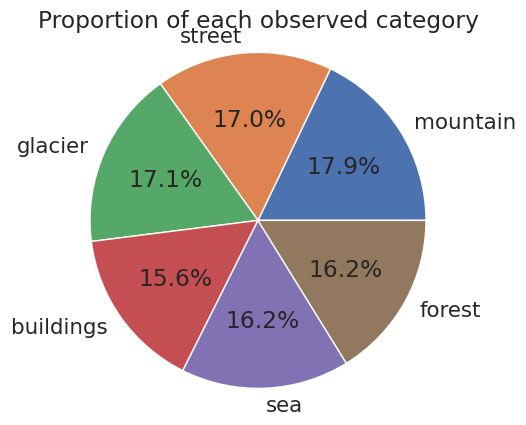

In [9]:
# plt to see the % of each label
import pandas as pd

_, train_counts = np.unique(train_labels, return_counts=True)
_, test_counts = np.unique(test_labels, return_counts=True)
plt.pie(train_counts,
        explode=(0, 0, 0, 0, 0, 0) , 
        labels=class_names,
        autopct='%1.1f%%')
plt.axis('equal')
plt.title('Proportion of each observed category')
plt.show()

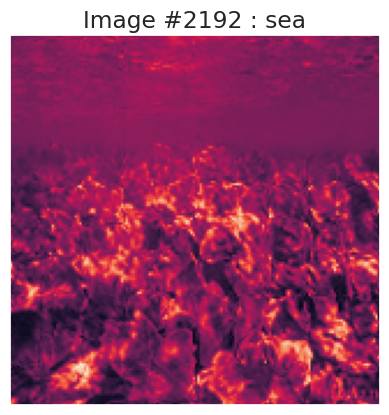

In [10]:
def display_random_image(class_names, images, labels):
    """
        Display a random image from the images array and its correspond label from the labels array.
    """
    
    index = np.random.randint(images.shape[0])
    plt.figure()
    plt.imshow(images[index])
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.title('Image #{} : '.format(index) + class_names[labels[index]])
    plt.show()


display_random_image(class_names, train_images, train_labels)

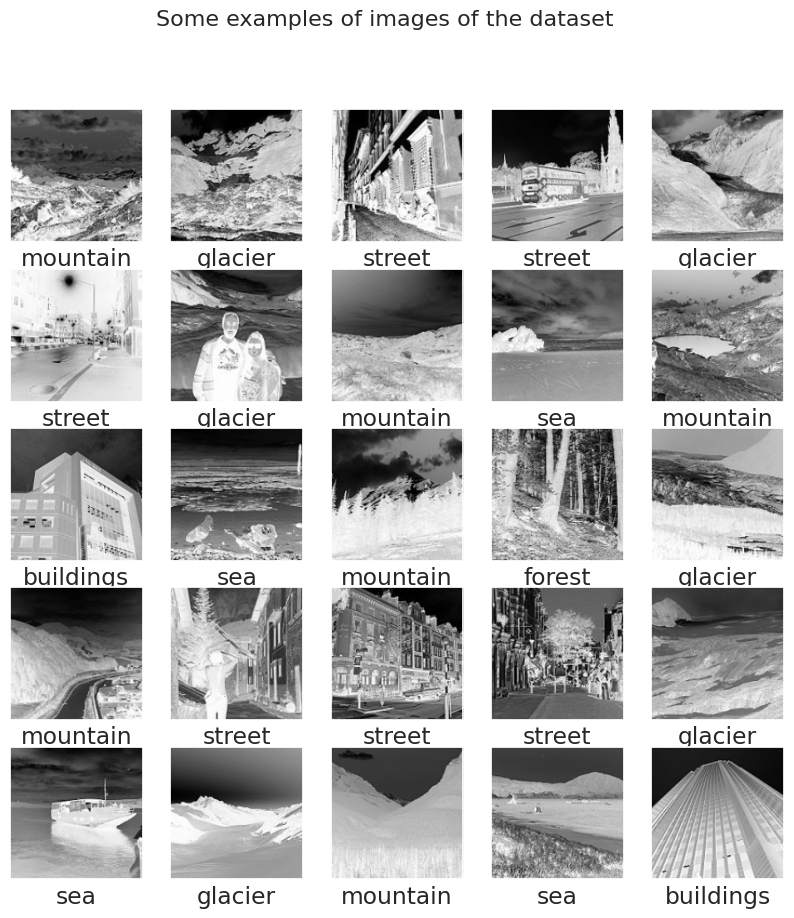

In [11]:
def display_examples(class_names, images, labels):
    """
        Display 25 images from the images array with its corresponding labels
    """
    
    fig = plt.figure(figsize=(10,10))
    fig.suptitle("Some examples of images of the dataset", fontsize=16)
    for i in range(25):
        plt.subplot(5,5,i+1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        plt.imshow(images[i], cmap=plt.cm.binary)
        plt.xlabel(class_names[labels[i]])
    plt.show()
display_examples(class_names, train_images, train_labels)

In [12]:
# Data augmentation
Data_augmentation= tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

2026-11-03 01:58:10.806360: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [13]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(160, 160, 1)),
    Data_augmentation,

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(6, activation='softmax')
])

In [14]:
# Callbacks are used to monitor and control the model training process.

callbacks = [

    # 1. EarlyStopping:
    # Stops training if the validation loss does not improve
    # from the epoch with the lowest validation loss.

    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',           # Monitor validation loss
        patience=5,                   # Wait 5 epochs without improvement
        restore_best_weights=True     # Restore the best model weights
    ),

    # 2. ModelCheckpoint:
    # Saves the best version of the model during training.
    # The model is saved only when validation loss improves.

    tf.keras.callbacks.ModelCheckpoint(
        'best_model.keras',           # File name to save the model
        monitor='val_loss',           # Monitor validation loss
        save_best_only=True           # Save only the best model
    ),

    # 3. ReduceLROnPlateau:
    # Reduces the learning rate when validation loss stops improving.
    # This helps the model make smaller updates during training.

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',           # Monitor validation loss
        factor=0.5,                   # Reduce learning rate by 50%
        patience=3                    # Wait 3 epochs before reducing it
    )
]

In [15]:
model.compile(optimizer = 'adam', loss = 'sparse_categorical_crossentropy', metrics=['accuracy'])

In [16]:
history = model.fit(train_images, train_labels, batch_size=128, epochs=20, validation_split = 0.2,callbacks=callbacks)

Epoch 1/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 337s 4s/step - accuracy: 0.3954 - loss: 1.4651 - val_accuracy: 0.4663 - val_loss: 1.3682 - learning_rate: 0.0010
Epoch 2/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 313s 4s/step - accuracy: 0.5292 - loss: 1.1852 - val_accuracy: 0.6081 - val_loss: 1.0239 - learning_rate: 0.0010
Epoch 3/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 313s 4s/step - accuracy: 0.5779 - loss: 1.0950 - val_accuracy: 0.6612 - val_loss: 0.8877 - learning_rate: 0.0010
Epoch 4/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 334s 4s/step - accuracy: 0.6141 - loss: 1.0196 - val_accuracy: 0.6915 - val_loss: 0.8299 - learning_rate: 0.0010
Epoch 5/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 312s 4s/step - accuracy: 0.6338 - loss: 0.9792 - val_accuracy: 0.6819 - val_loss: 0.8636 - learning_rate: 0.0010
Epoch 6/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 342s 4s/step - accuracy: 0.6577 - loss: 0.9102 - val_accuracy: 0.6829 - val_loss: 0.8753 - learning_rate: 0.0010
Epoch 7/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 312s 4s/step - accuracy: 0.6701 - loss: 0.8916 - val_acc

In [17]:
def plot_accuracy_loss(history):

    fig = plt.figure(figsize=(12, 5))

    # Plot accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], 'bo--', label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], 'ro--', label='Validation Accuracy')
    plt.title('Training Accuracy vs Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Plot loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], 'bo--', label='Training Loss')
    plt.plot(history.history['val_loss'], 'ro--', label='Validation Loss')
    plt.title('Training Loss vs Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

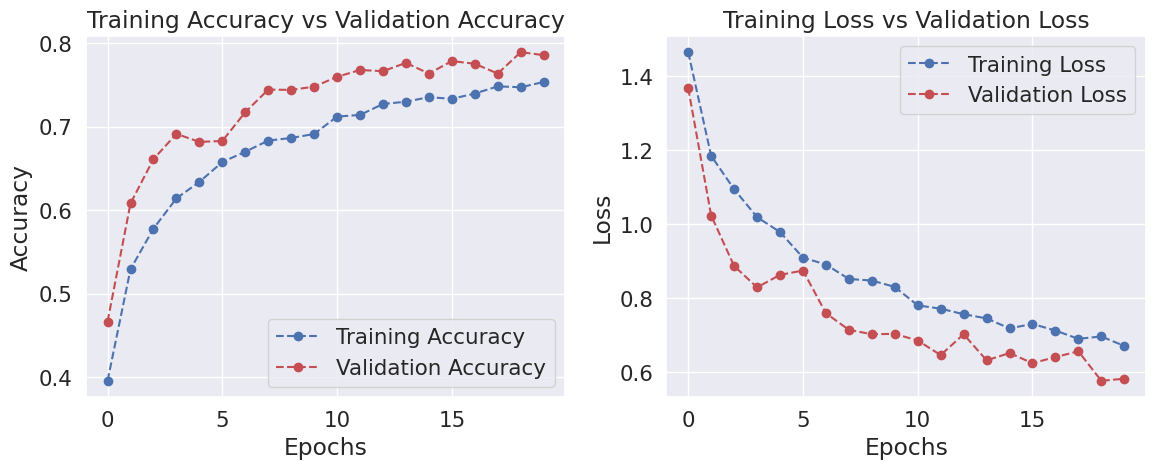

In [18]:
plot_accuracy_loss(history)


In [19]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)


predictions = model.predict(test_images)     # Vector of probabilities
pred_labels = np.argmax(predictions, axis = 1) # We take the highest probability


print(classification_report(
    test_labels,
    pred_labels,
    target_names=class_names
))

94/94 ━━━━━━━━━━━━━━━━━━━━ 21s 227ms/step
              precision    recall  f1-score   support

    mountain       0.79      0.65      0.71       525
      street       0.79      0.89      0.83       501
     glacier       0.66      0.81      0.73       553
   buildings       0.84      0.75      0.79       437
         sea       0.79      0.69      0.74       510
      forest       0.95      0.97      0.96       474

    accuracy                           0.79      3000
   macro avg       0.80      0.79      0.79      3000
weighted avg       0.80      0.79      0.79      3000



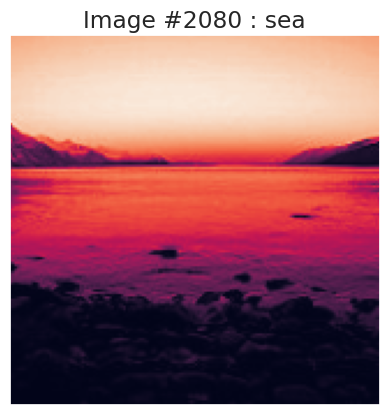

In [20]:
display_random_image(class_names, test_images, pred_labels)

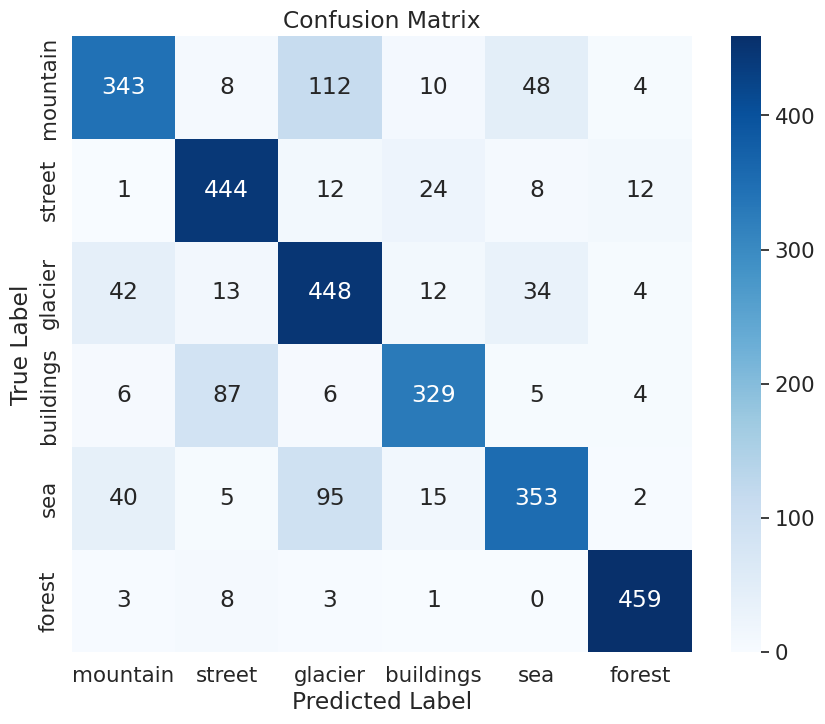

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(test_labels, pred_labels)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [22]:
test_loss, test_accuracy = model.evaluate(test_images, test_labels)
train_loss, train_accuracy = model.evaluate(train_images, train_labels)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

print("Test Loss:",   train_loss)
print("Test Accuracy:", train_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 21s 226ms/step - accuracy: 0.7920 - loss: 0.5718
439/439 ━━━━━━━━━━━━━━━━━━━━ 100s 228ms/step - accuracy: 0.8055 - loss: 0.5223
Test Loss: 0.5718178153038025
Test Accuracy: 0.7919999957084656
Test Loss: 0.5223361253738403
Test Accuracy: 0.8055436611175537


In [23]:
def print_mislabeled_images(class_names, test_images, test_labels, pred_labels):
    """
        Print 25 examples of mislabeled images by the classifier, e.g when test_labels != pred_labels
    """
    BOO = (test_labels == pred_labels)
    mislabeled_indices = np.where(BOO == 0)
    mislabeled_images = test_images[mislabeled_indices]
    mislabeled_labels = pred_labels[mislabeled_indices]

    title = "Some examples of mislabeled images by the classifier:"
    display_examples(class_names,  mislabeled_images, mislabeled_labels)

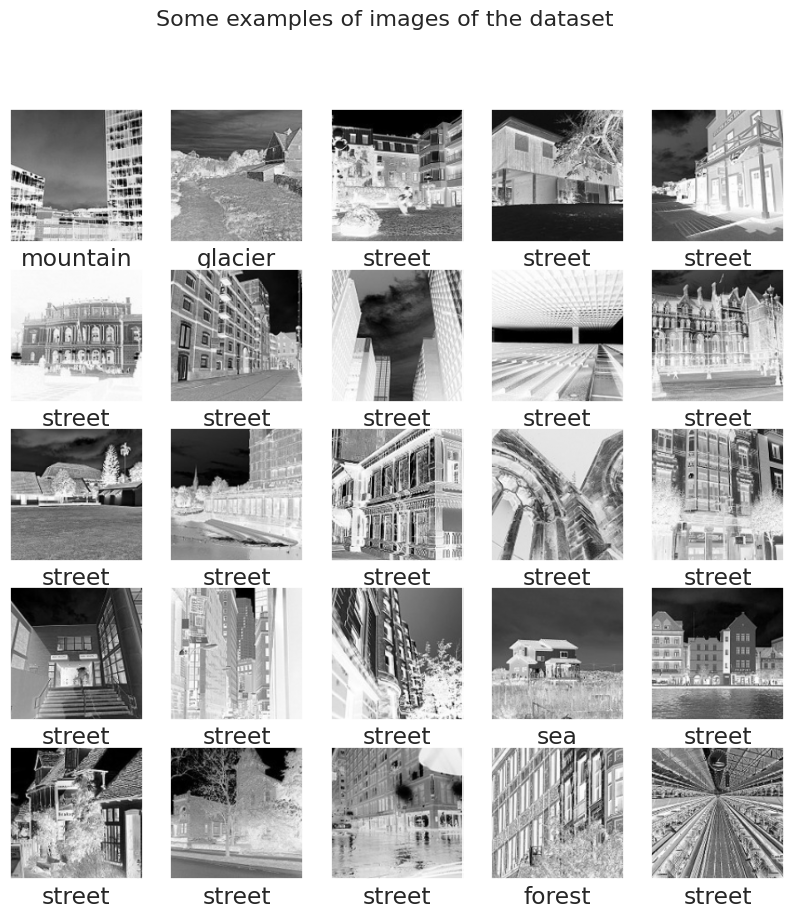

In [24]:
print_mislabeled_images(class_names, test_images, test_labels, pred_labels)